Article: High Injury Network of Roads in Pittsburgh

https://data.wprdc.org/dataset/high-injury-network/resource/f66956f7-0099-40c0-b316-e97cd1360ceb?view_id=889c8815-d280-40d7-98a4-7d22c0474c19

Fifth Avenue and Point Breeze North have the highest amount of crashes that result in an injury, both have over 600 reported crashes. From the data, these two areas in Pittsburgh have the highest crash injuries. 

Seventh Avenue (7th Ave, Pittsburgh, PA) is reported to be the area that has the leaste amount of total crashes with only 43 reported in April of 2026. 

In [59]:
import pandas as pd

In [60]:
traffic = pd.read_csv("HighInjuryNetwork.csv")
traffic.head()

,_id,CATEGORY,Complete_Streets,Count_AllCrash,Count_BicycleCrash,Count_FatalCrash,Count_InjuryCrash,Count_PedestrianCrash,Count_SuspectedSeriousCrash,Fatal22,...,hood_left,hood_right,no_lanes,num_lanes,roadclass,roadwidth,rsroadclas,speedlimit,streetname,geometry
0,1,PED/BIC/VRU,NaN,765,10,4,302,63,19,NaN,...,POINT BREEZE NORTH,POINT BREEZE,0,0,Primary,NaN,PRIMARY,35.0,PENN AVE,MULTILINESTRING ((584458.3043081491487101 4477...
1,2,NaN,NaN,112,1,0,46,8,5,NaN,...,EAST LIBERTY,FRIENDSHIP,2,2,Primary,60.0,PRIMARY,25.0,S NEGLEY AVE,LINESTRING (590362.3159295885125175 4479091.14...
2,3,PED/VRU,NaN,673,5,5,257,81,34,NaN,...,CENTRAL BUSINESS DISTRICT,CENTRAL BUSINESS DISTRICT,3,3,Primary,38.5,PRIMARY,25.0,FIFTH AVE,MULTILINESTRING ((584543.9677332326536998 4477...
3,4,PED,NaN,242,1,1,98,13,28,NaN,...,LARIMER,LARIMER,2,2,Primary,36.0,PRIMARY,25.0,FRANKSTOWN AVE,MULTILINESTRING ((594990.6055558335501701 4478...
4,5,BIC,NaN,149,0,0,50,3,1,NaN,...,GREENFIELD,GREENFIELD,2,2,Primary,40.0,PRIMARY,25.0,BEECHWOOD BLVD,LINESTRING (591014.7044224431738257 4474885.12...


In [61]:
traffic.columns

Index(['_id', 'CATEGORY', 'Complete_Streets', 'Count_AllCrash',
       'Count_BicycleCrash', 'Count_FatalCrash', 'Count_InjuryCrash',
       'Count_PedestrianCrash', 'Count_SuspectedSeriousCrash', 'Fatal22',
       'Field', 'Num_Projects', 'OBJECTID_1', 'Shape__Length', 'Sidewalk',
       'Traffic_Calming', 'Traffic_Signals', 'areasqft', 'cdbg', 'council201',
       'council2_1', 'council_lt', 'council_rt', 'domi_class', 'hood_left',
       'hood_right', 'no_lanes', 'num_lanes', 'roadclass', 'roadwidth',
       'rsroadclas', 'speedlimit', 'streetname', 'geometry'],
      dtype='object')

In [62]:
traffic[["hood_left", "hood_right", "Count_InjuryCrash"]].head(10)

,hood_left,hood_right,Count_InjuryCrash
0,POINT BREEZE NORTH,POINT BREEZE,302
1,EAST LIBERTY,FRIENDSHIP,46
2,CENTRAL BUSINESS DISTRICT,CENTRAL BUSINESS DISTRICT,257
3,LARIMER,LARIMER,98
4,GREENFIELD,GREENFIELD,50
5,LARIMER,LINCOLN-LEMINGTON-BELMAR,71
6,SQUIRREL HILL NORTH,SQUIRREL HILL SOUTH,85
7,HOMEWOOD WEST,HOMEWOOD WEST,15
8,EAST HILLS,EAST HILLS,75
9,HAZELWOOD,HAZELWOOD,16


##The Top 10 Neighborhoods for Traffic Safety in Pittsburgh According to the Data

In [63]:
# Get the columns we need
injuries = traffic[
    ["hood_left", "hood_right", "Count_InjuryCrash"]
].copy()

# Get the left side neighborhoods
left = injuries[["hood_left", "Count_InjuryCrash"]].copy()
left.columns = ["Neighborhood", "InjuryCrashes"]
left["InjuryCrashes"] = left["InjuryCrashes"] / 2

# Get the right side neighborhoods
right = injuries[["hood_right", "Count_InjuryCrash"]].copy()
right.columns = ["Neighborhood", "InjuryCrashes"]
right["InjuryCrashes"] = right["InjuryCrashes"] / 2

# Put both sides together
combined = pd.concat([left, right])

# Add up the injury crashes for each neighborhood
neighborhood_injuries = (
    combined.groupby("Neighborhood")["InjuryCrashes"]
    .sum()
    .sort_values()
)

# Show the 10 neighborhoods with the lowest counts
neighborhood_injuries.head(10)

Neighborhood
UPPER LAWRENCEVILLE      1.0
SOUTH SHORE              2.0
CALIFORNIA-KIRKBRIDE     3.0
SOUTH OAKLAND            3.5
FAIRYWOOD                4.0
CRAFTON HEIGHTS          5.0
ST. CLAIR                6.0
HOMEWOOD NORTH           6.0
MANCHESTER               6.5
SPRING HILL-CITY VIEW    7.0
Name: InjuryCrashes, dtype: float64

A Graph of Traffic Safety for Pittsburgh Neighboorhoods According to the Data

In [64]:
average_neighborhood_injuries = (
    combined.groupby("Neighborhood")["InjuryCrashes"]
    .mean()
    .sort_values()
)
average_neighborhood_injuries.head(10)

Neighborhood
UPPER LAWRENCEVILLE      1.000000
SOUTH SHORE              2.000000
CRAFTON HEIGHTS          2.500000
CALIFORNIA-KIRKBRIDE     3.000000
HOMEWOOD NORTH           3.000000
SOUTH OAKLAND            3.500000
SPRING HILL-CITY VIEW    3.500000
FAIRYWOOD                4.000000
HIGHLAND PARK            4.333333
BRIGHTON HEIGHTS         5.000000
Name: InjuryCrashes, dtype: float64

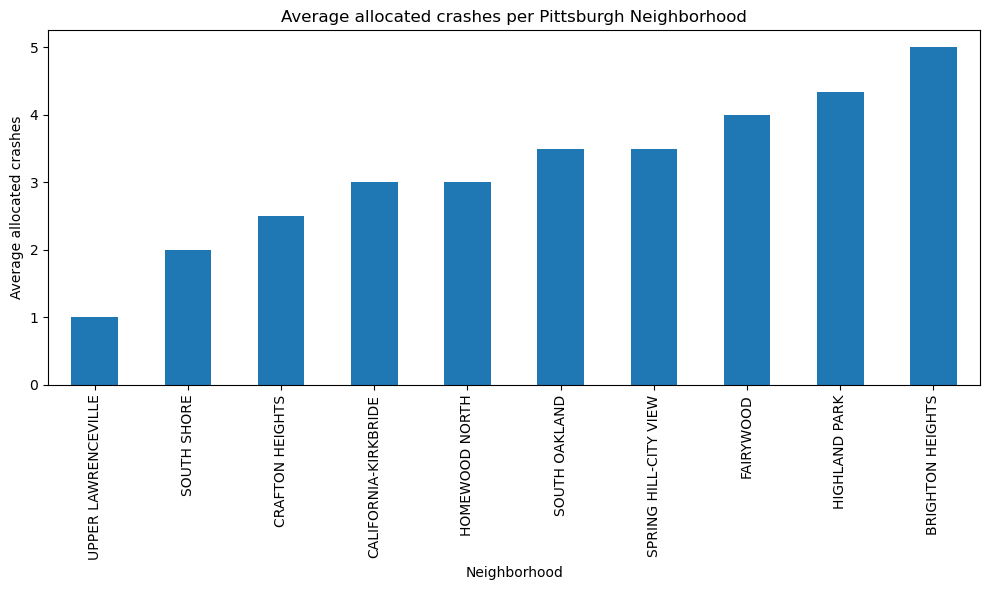

In [65]:
import matplotlib.pyplot as plt

# Get the 10 neighborhoods with the lowest injury counts
average_top_10 = average_neighborhood_injuries.head(10)

# Make a bar graph
average_top_10.plot(kind="bar", figsize=(10, 6))

plt.title("Average allocated crashes per Pittsburgh Neighborhood")
plt.xlabel("Neighborhood")
plt.ylabel("Average allocated crashes")
plt.tight_layout()
plt.show()

### Conclusion

Based on my analysis of the High Injury Network dataset, Upper Lawrenceville had the lowest average allocated injury-crash count of the Pittsburgh neighborhoods included in the data. I looked at the neighborhoods on both sides of each road segment and divided the injury crashes between them to estimate how many crashes could be associated with each neighborhood.

I compared average allocated injury crashes to account for neighborhoods appearing a different number of times in the dataset. However, this does not account for road length, traffic volume, or population. The dataset also only includes High Injury Network roads, so my results do not necessarily mean Upper Lawrenceville is the safest neighborhood overall.

Based on the information available, Upper Lawrenceville ranked best for my traffic-safety metric.